## Mô Hình M1: LeNet Baseline Từ Số 0 (Mốc Tham Chiếu)

Báo cáo kiến trúc, huấn luyện và đánh giá mô hình Baseline **M1LeNet** trên tập dữ liệu biển báo giao thông GTSRB.

**Mục tiêu chính**:
1. Xây dựng mô hình CNN cổ điển kiểu LeNet từ số 0 (from scratch): 2 block Conv-Pool kết hợp 2 lớp Fully-Connected (Dense).
2. Phân tích tham số định lượng: Chứng minh thực nghiệm rằng **97.3% tham số** của mô hình tập trung ở duy nhất một lớp kết nối dày đặc `Linear(9216, 256)`.
3. Thiết lập mốc tham chiếu khoa học (Baseline): Cố ý **không** sử dụng Batch Normalization, Residual Connection hay Spatial Dropout để làm cơ sở đối chứng minh bạch cho các cải tiến của mô hình M2.

## 1. Khởi tạo Môi trường và Thiết lập Cấu hình Tham số

### 1.1. Khởi tạo thư viện và chuyển thư mục làm việc về gốc

In [1]:
import os
import math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, precision_recall_fscore_support

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import v2

# Thiết lập thư mục gốc của dự án
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
print(f"Thư mục làm việc: {Path.cwd()}")

Thư mục làm việc: d:\code\Python\DSEB_ex\DL\gtsrb-model-comparison


### 1.2. Thiết lập cờ điều khiển và tham số thực thi
* `FORCE_RETRAIN = False`: Mặc định nạp checkpoint đã huấn luyện từ `checkpoints/m1_lenet_best.pt` để xuất kết quả ngay lập tức.
* `DEMO_EPOCHS = 2`: Số epoch chạy thử nghiệm nếu người dùng muốn quan sát quá trình huấn luyện trực tiếp.

In [2]:
FORCE_RETRAIN = False       # Đặt True nếu muốn huấn luyện lại từ đầu
DEMO_EPOCHS = 2            # Số epoch huấn luyện demo
FULL_EPOCHS = 30           # Số epoch huấn luyện đầy đủ
BATCH_SIZE = 64
LR = 0.001

INDEX_CSV = Path("data/processed/index.csv")
CKPT_PATH = Path("checkpoints/m1_lenet_best.pt")
IMG_SIZE = 48

DEVICE = torch.device("cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu"))
print(f"Thiết bị tính toán: {DEVICE}")

Thiết bị tính toán: cpu


## 2. Pipeline Dữ Liệu (Dataset & DataLoader)

### 2.1. Hằng số và Quy chuẩn Tiền Xử Lý
* **Thống kê chuẩn hóa GTSRB**: `mean=(0.4597, 0.4254, 0.4376)`, `std=(0.2670, 0.2607, 0.2691)` được tính toán **chỉ trên tập train** để ngăn ngừa rò rỉ thống kê từ tập kiểm thử.
* **Quy tắc Augmentation**: Áp dụng xoay ngẫu nhiên $\pm 15^\circ$, dịch $\pm 10\%$, zoom $0.9 - 1.1$, và biến đổi độ sáng/tương phản $\pm 0.2$.
* **Các biến đổi bị cấm**: Nghiêm cấm lật ngang (`RandomHorizontalFlip`) vì làm đảo ngược ngữ nghĩa (ví dụ biển rẽ phải lớp 33 biến thành biển rẽ trái lớp 34); cấm thay đổi Hue/Saturation vì màu sắc là đặc trưng phân loại cốt lõi.

In [3]:
NUM_CLASSES = 43
GTSRB_MEAN = (0.4597, 0.4254, 0.4376)
GTSRB_STD = (0.2670, 0.2607, 0.2691)

def _build_normalize(mean=GTSRB_MEAN, std=GTSRB_STD) -> v2.Transform:
    """Chuyển đổi tensor uint8 [0, 255] sang float32 [0.0, 1.0] và chuẩn hóa mean/std."""
    return v2.Compose([
        v2.ToDtype(torch.float32, scale=True),
        v2.Normalize(mean=list(mean), std=list(std)),
    ])

def build_train_transform(img_size: int = 48) -> v2.Transform:
    """Biến đổi hình học và quang học hợp lệ cho tập train."""
    return v2.Compose([
        v2.RandomAffine(degrees=15.0, translate=(0.10, 0.10), scale=(0.9, 1.1),
                        interpolation=v2.InterpolationMode.BILINEAR, fill=0),
        v2.ColorJitter(brightness=0.20, contrast=0.20),
    ])

### 2.2. Lớp Dữ Liệu `GTSRBDataset`
Lớp nạp dữ liệu đọc trực tiếp từ tệp bộ đệm `images_48_clahe.npy` qua cơ chế Memory Mapping (`mmap_mode='r'`), cho phép các tiến trình chia sẻ bộ đệm chung mà không tốn tài nguyên RAM.

In [4]:
class GTSRBDataset(Dataset):
    """Dataset nạp dữ liệu GTSRB từ file index.csv và cache .npy."""
    def __init__(self, index_csv: str | Path, split: str, img_size: int = 48,
                 preprocess: str = "clahe", normalize: str = "gtsrb",
                 processed_dir: str | Path = "data/processed",
                 cache_size: int = 48, transform=None) -> None:
        if split not in ("train", "val", "test"):
            raise ValueError(f"Split không hợp lệ: {split}")
        self.split = split
        self.img_size = img_size
        self.transform = transform

        frame = pd.read_csv(index_csv)
        self.frame = frame[frame["split"] == split].reset_index(drop=True)
        self._cache_rows = frame.index[frame["split"] == split].to_numpy()

        self.normalizer = _build_normalize(GTSRB_MEAN, GTSRB_STD)

        path = Path(processed_dir) / f"images_{cache_size}_{preprocess}.npy"
        if not path.exists():
            raise FileNotFoundError(f"Không tìm thấy tệp cache {path}. Hãy chạy 01_preprocess.ipynb trước.")
        self.cache = np.load(path, mmap_mode="r")

    def __len__(self) -> int:
        return len(self.frame)

    def __getitem__(self, i: int):
        image = np.array(self.cache[self._cache_rows[i]], copy=True)  # HWC uint8
        label = int(self.frame.iloc[i]["class_id"])
        tensor = torch.from_numpy(np.ascontiguousarray(image)).permute(2, 0, 1)  # CHW

        if self.transform is not None:
            tensor = self.transform(tensor)

        return self.normalizer(tensor), label

### 2.3. Khởi tạo DataLoaders
Tạo các DataLoader cho tập Train (có shuffle và drop_last), Validation và Test (không shuffle).

In [5]:
def make_loader(index_csv: str | Path, split: str, img_size: int = 48, batch_size: int = 64,
                transform=None, num_workers: int = 0) -> DataLoader:
    ds = GTSRBDataset(index_csv, split, img_size=img_size, transform=transform)
    is_train = split == "train"
    return DataLoader(ds, batch_size=batch_size, shuffle=is_train, drop_last=is_train, num_workers=num_workers)

train_tf = build_train_transform(IMG_SIZE)
train_loader = make_loader(INDEX_CSV, "train", img_size=IMG_SIZE, batch_size=BATCH_SIZE, transform=train_tf)
val_loader = make_loader(INDEX_CSV, "val", img_size=IMG_SIZE, batch_size=BATCH_SIZE)
test_loader = make_loader(INDEX_CSV, "test", img_size=IMG_SIZE, batch_size=BATCH_SIZE)

print(f"Khởi tạo DataLoader thành công: Train={len(train_loader.dataset)}, Val={len(val_loader.dataset)}, Test={len(test_loader.dataset)} mẫu.")

Khởi tạo DataLoader thành công: Train=31379, Val=7830, Test=12630 mẫu.


## 3. Định Nghĩa Kiến Trúc Mô Hình `M1LeNet`

### 3.1. Thiết kế mạng và Luận điểm cấu trúc
Kiến trúc gồm 2 khối trích xuất đặc trưng Conv-Pool và 2 lớp Fully-Connected:
* `Conv2d(3, 32, kernel_size=5, padding=2)` $\rightarrow$ `ReLU` $\rightarrow$ `MaxPool2d(2)`: Feature map $(B, 32, 24, 24)$
* `Conv2d(32, 64, kernel_size=5, padding=2)` $\rightarrow$ `ReLU` $\rightarrow$ `MaxPool2d(2)`: Feature map $(B, 64, 12, 12)$
* `Flatten`: Vector $(B, 9216)$
* `Linear(9216, 256)` $\rightarrow$ `ReLU` $\rightarrow$ `Dropout(0.5)`
* `Linear(256, 43)` $\rightarrow$ Logits phân loại $(B, 43)$

In [6]:
class M1LeNet(nn.Module):
    """Mô hình Baseline kiểu LeNet: 2 block Conv-Pool + 2 lớp Linear."""
    def __init__(self, num_classes: int = NUM_CLASSES, img_size: int = 48) -> None:
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=5, padding=2),   # (B, 32, 48, 48)
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),                              # (B, 32, 24, 24)
            nn.Conv2d(32, 64, kernel_size=5, padding=2),  # (B, 64, 24, 24)
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),                              # (B, 64, 12, 12)
        )

        # Tự động tính số chiều sau khi duỗi phẳng thay vì hardcode 9216
        with torch.no_grad():
            dummy = torch.zeros(1, 3, img_size, img_size)
            flat_dim = self.features(dummy).flatten(1).shape[1]

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(flat_dim, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.classifier(self.features(x))

### 3.2. Phân Tích Định Lượng Tham Số và Điểm Nghẽn Cấu Trúc
Hàm `parameter_table` thống kê số lượng tham số của từng tầng trong mô hình.

In [7]:
def parameter_table(model: nn.Module) -> pd.DataFrame:
    """Thống kê số lượng tham số của từng lớp theo thứ tự giảm dần."""
    rows = []
    total = sum(p.numel() for p in model.parameters())
    for name, module in model.named_modules():
        own = sum(p.numel() for p in module.parameters(recurse=False))
        if own > 0:
            rows.append({
                "Lớp": name or "(root)",
                "Loại module": type(module).__name__,
                "Số tham số": own,
                "Tỷ lệ (%)": round(100.0 * own / total, 2)
            })
    df = pd.DataFrame(rows).sort_values("Số tham số", ascending=False).reset_index(drop=True)
    print(f"Tổng số tham số: {total:,}")
    return df

model_demo = M1LeNet()
param_df = parameter_table(model_demo)
display(param_df)

Tổng số tham số: 2,424,299


,Lớp,Loại module,Số tham số,Tỷ lệ (%)
0,classifier.1,Linear,2359552,97.33
1,features.3,Conv2d,51264,2.11
2,classifier.4,Linear,11051,0.46
3,features.0,Conv2d,2432,0.10


> **Kết luận quan sát**: Lớp `classifier.1` (`Linear(9216, 256)`) chiếm tới **2.359.552 tham số**, tương đương **97.33%** tổng tham số của toàn bộ mô hình! Đây chính là hạn chế kinh điển của kiến trúc LeNet cổ điển, tạo tiền đề để mô hình M2 thay thế toàn bộ cụm `Flatten + Linear` bằng `Global Average Pooling (GAP)`.

## 4. Hàm Mất Mát, Thuật Toán Tối Ưu và Vòng Lặp Huấn Luyện

### 4.1. Định nghĩa các hàm đo lường chất lượng
* **Chỉ số chính**: **Macro-F1** (tính trung bình F1 trên cả 43 lớp). Do tập dữ liệu mất cân bằng 10.7:1 (lớp đông nhất có 2.250 ảnh, lớp ít nhất chỉ có 210 ảnh), accuracy thông thường sẽ che giấu sai sót ở các lớp thiểu số.
* **Các chỉ số phụ**: Top-1 Accuracy, Top-5 Accuracy, Weighted-F1.

In [8]:
@torch.no_grad()
def predict(model: nn.Module, loader: DataLoader, device: torch.device) -> tuple[np.ndarray, np.ndarray]:
    model.eval()
    probs, targets = [], []
    for images, y in loader:
        logits = model(images.to(device))
        probs.append(torch.softmax(logits.float(), dim=1).cpu())
        targets.append(y)
    return torch.cat(targets).numpy(), torch.cat(probs).numpy()

def compute_metrics(y_true: np.ndarray, y_prob: np.ndarray) -> dict:
    y_pred = y_prob.argmax(axis=1)
    top1 = float((y_pred == y_true).mean())
    top5_idx = np.argsort(-y_prob, axis=1)[:, :5]
    top5 = float((top5_idx == y_true[:, None]).any(axis=1).mean())

    labels = list(range(NUM_CLASSES))
    macro_f1 = float(f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0))
    weighted_f1 = float(f1_score(y_true, y_pred, labels=labels, average="weighted", zero_division=0))
    prec, rec, f1, support = precision_recall_fscore_support(y_true, y_pred, labels=labels, zero_division=0)
    per_class = pd.DataFrame({"class_id": labels, "precision": prec, "recall": rec, "f1": f1, "support": support})
    return {"top1": top1, "top5": top5, "macro_f1": macro_f1, "weighted_f1": weighted_f1,
            "per_class": per_class, "y_true": y_true, "y_pred": y_pred}

def evaluate(model: nn.Module, loader: DataLoader, device: torch.device) -> dict:
    y_true, y_prob = predict(model, loader, device)
    return compute_metrics(y_true, y_prob)

### 4.2. Vòng lặp huấn luyện từng epoch

In [9]:
def train_one_epoch(model: nn.Module, loader: DataLoader, criterion: nn.Module,
                    optimizer: torch.optim.Optimizer, device: torch.device, clip_norm: float = 1.0) -> float:
    model.train()
    total_loss = 0.0
    for images, targets in loader:
        images, targets = images.to(device), targets.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, targets)
        loss.backward()
        if clip_norm > 0:
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=clip_norm)
        optimizer.step()
        total_loss += loss.item() * len(targets)
    return total_loss / len(loader.dataset)

### 4.3. Hàm điều phối huấn luyện hoàn chỉnh `train_m1`

In [10]:
def train_m1(epochs: int = 30, lr: float = 1e-3, save_path: Path = CKPT_PATH) -> M1LeNet:
    model = M1LeNet().to(DEVICE)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-5)

    best_f1 = 0.0
    save_path.parent.mkdir(parents=True, exist_ok=True)
    print(f"Bắt đầu huấn luyện M1LeNet ({epochs} epochs)...\n")

    for epoch in range(1, epochs + 1):
        loss = train_one_epoch(model, train_loader, criterion, optimizer, DEVICE)
        val_metrics = evaluate(model, val_loader, DEVICE)
        scheduler.step()

        val_f1 = val_metrics["macro_f1"]
        val_top1 = val_metrics["top1"]
        is_best = val_f1 > best_f1
        if is_best:
            best_f1 = val_f1
            torch.save(model.state_dict(), save_path)

        tag = "* [BEST]" if is_best else ""
        print(f"Epoch {epoch:02d}/{epochs:02d} | Train Loss: {loss:.4f} | Val Top-1: {val_top1*100:.2f}% | Val Macro-F1: {val_f1:.4f} {tag}")

    print(f"\nHuấn luyện hoàn tất. Checkpoint tốt nhất lưu tại: {save_path}")
    ckpt = torch.load(save_path, map_location=DEVICE, weights_only=False)
    state = ckpt["model_state"] if isinstance(ckpt, dict) and "model_state" in ckpt else ckpt
    model.load_state_dict(state)
    return model

## 5. Thực Thi: Nạp Checkpoint Hoặc Huấn Luyện Mới

Kiểm tra cờ `FORCE_RETRAIN`:
* Nếu `FORCE_RETRAIN = False` và checkpoint đã tồn tại: Nạp trực tiếp trọng số để sẵn sàng đánh giá.
* Nếu `FORCE_RETRAIN = True`: Bắt đầu vòng lặp huấn luyện.

In [11]:
model = M1LeNet().to(DEVICE)

if not FORCE_RETRAIN and CKPT_PATH.exists():
    print(f"[Tài nguyên sẵn sàng] Nạp checkpoint mô hình từ {CKPT_PATH}")
    ckpt = torch.load(CKPT_PATH, map_location=DEVICE, weights_only=False)
    state_dict = ckpt["model_state"] if isinstance(ckpt, dict) and "model_state" in ckpt else ckpt
    model.load_state_dict(state_dict)
    print("Nạp trọng số thành công.")
else:
    epochs_to_run = DEMO_EPOCHS if not FORCE_RETRAIN else FULL_EPOCHS
    print(f"[Thực thi] Bắt đầu huấn luyện mô hình ({epochs_to_run} epoch)...\n")
    model = train_m1(epochs=epochs_to_run, lr=LR)

[Tài nguyên sẵn sàng] Nạp checkpoint mô hình từ checkpoints\m1_lenet_best.pt
Nạp trọng số thành công.


## 6. Báo Cáo Kết Quả Đánh Giá Trên Tập Test Chính Thức

### 6.1. Đánh giá tổng hợp trên 12.630 ảnh kiểm thử

In [12]:
test_metrics = evaluate(model, test_loader, DEVICE)

print("=" * 50)
print("KẾT QUẢ KIỂM THỬ MÔ HÌNH M1 (LeNet)")
print("=" * 50)
print(f"Top-1 Accuracy : {test_metrics['top1'] * 100:.2f}%")
print(f"Top-5 Accuracy : {test_metrics['top5'] * 100:.2f}%")
print(f"Macro-F1       : {test_metrics['macro_f1']:.4f}")
print(f"Weighted-F1    : {test_metrics['weighted_f1']:.4f}")
print("=" * 50)

KẾT QUẢ KIỂM THỬ MÔ HÌNH M1 (LeNet)
Top-1 Accuracy : 98.46%
Top-5 Accuracy : 99.85%
Macro-F1       : 0.9778
Weighted-F1    : 0.9845


### 6.2. Trực quan hóa phân bố Macro-F1 theo từng lớp
Phân tích sự chênh lệch hiệu năng giữa các lớp biển báo.

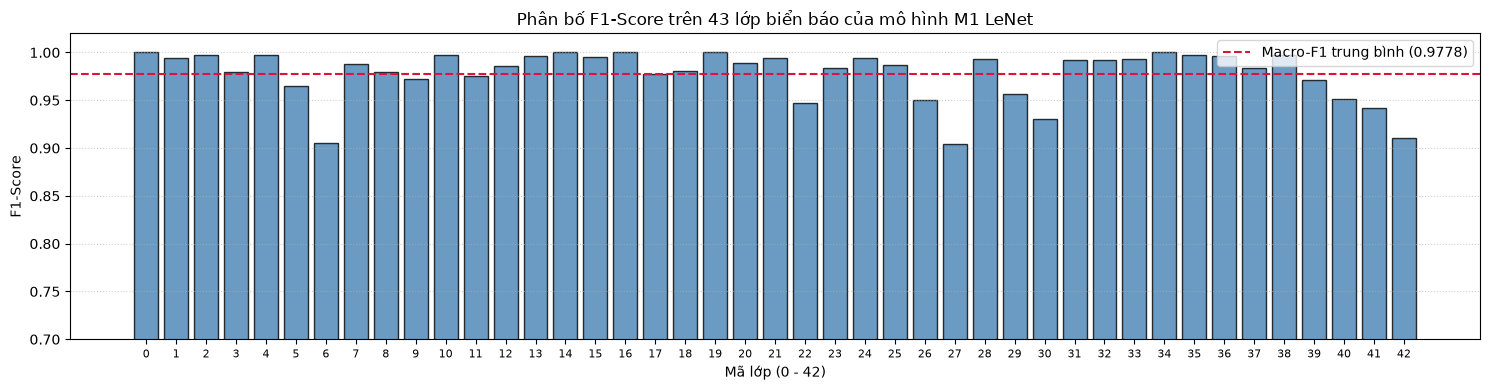

In [13]:
per_class_df = test_metrics["per_class"]

plt.figure(figsize=(15, 4))
plt.bar(per_class_df["class_id"], per_class_df["f1"], color="steelblue", edgecolor="black", alpha=0.8)
plt.axhline(test_metrics["macro_f1"], color="crimson", linestyle="--", label=f"Macro-F1 trung bình ({test_metrics['macro_f1']:.4f})")
plt.xlabel("Mã lớp (0 - 42)")
plt.ylabel("F1-Score")
plt.title("Phân bố F1-Score trên 43 lớp biển báo của mô hình M1 LeNet")
plt.xticks(range(NUM_CLASSES), fontsize=8)
plt.ylim(0.7, 1.02)
plt.legend()
plt.grid(axis="y", linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()